# 03. Lead-window difference maps

## Purpose

Show where the differences of the comparisons A − B (`COMPARISONS`) occur, as lead-window means (days 1-3, 4-10, 11-28, 29-56). Stippling marks gridpoints where |A − B| exceeds twice the noise scale (√2 × the gridpoint spread of the 20 DA_COUPLED members in that window), so only differences that member-to-member chaos alone is unlikely to produce are marked.

Issues found in the ERA5-initialized F20TR hindcasts (HYB_BASE, DA_LND) and tested here, all from the start of 16 Dec 2011:

1. **Incomplete ERA5 atmosphere.** `DART_INIT/ATM/v3.LR.ne30pg2.ERA5.eam.i.<date>.nc` holds only T, U, V, Q, PS, CLDLIQ and CLDICE, and EAM starts every missing field from zero. That includes the radiation's gases (`rad_climate` reads H2OLNZ, O3, N2OLNZ and CH4LNZ), the aerosols and the hydrometeor numbers. HYB_BASE and DA_LND therefore start radiatively dry and without ozone, about 6 K too cold over land.
2. **Which fields fill the gap.** The completed states take ERA5's T, U, V, Q, PS, CLDLIQ and CLDICE and everything else from either the DART ensemble mean (`ERA5_DARTFILL`, the HYB_BASE rebuild) or the free-running CLIM_BASE state (`ERA5_CLIMFILL`). `ensemble_perturbations/util/complete_era5_ic.py` does the completion. H2OLNZ follows the ERA5 Q.
3. **Atmosphere and land benefits with complete states.** The production DA_LND (bare ERA5 atmosphere) and DA_ATM (DATM land) mix the IC defect into the component contrasts. CLIMO_ATM and CLIMO_LND instead replace one component of DA_COUPLED EN40 with the complete CLIM_BASE state (Berner-style).

Every test is a single member, so a difference A − B is judged against `ev.noise_scale`: √2 × the member spread of the 20-member DA_COUPLED ensemble of the same start. Beyond the first days, a difference smaller than this cannot be told apart from the chaotic divergence of two members.

## Inputs and outputs

Model and ensemble daily fields as in notebook 02. Outputs: `data/era5_ic_test/maps/window_maps_<VAR>.nc` (differences and noise scale by comparison and window); figures `figure/era5_ic_test/maps/maps_<VAR>.png` (rows: windows; columns: comparisons).

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")            # production F20TR hindcasts
TEST_DATA_ROOT = Path("/pscratch/sd/z/zhan391/e3sm_dart/simulation")             # the test runs
IC_ROOT = Path("/global/cfs/cdirs/m4849/zhan391")                                  # initial-file library (DART_INIT/, e3sm_dart/)
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                     # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"
WORKFLOW_NAME = "era5_ic_test"

RUN_KEYS = ("ERA5_BARE", "ERA5_DARTFILL", "ERA5_CLIMFILL", "DA_COUPLED", "DA_ATM", "DA_LND", "CLIMO_ATM", "CLIMO_LND")
ENSEMBLE_RUN = "DA_COUPLED"
MAX_MEMBERS = None
MAX_LEAD = 56
COMPARISON_KEYS = ("tracer_fix", "fill_source", "atm_clim", "atm_bare_era5", "lnd_clim", "lnd_datm")
VARIABLES = ("TREFHT", "T850", "TOZ", "FLDS", "PRECT")
WINDOWS = {"days 1-3": (1, 3), "days 4-10": (4, 10), "days 11-28": (11, 28), "days 29-56": (29, 56)}
# shading limits per variable (symmetric); others use the 98th percentile of |A - B|
LIMITS = {"TREFHT": 6.0, "T850": 4.0, "TOZ": 100.0, "FLDS": 40.0, "PRECT": 4.0}
TOPIC = "maps"
FORCE_COMPUTE = False
FIGURE_DPI = 150
SHOW = True

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
for p in (repo / "era5_ic_test", repo / "diagnostic"):     # ic_util (this directory), util (shared readers)
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from ic_util import ic_test_eval as ev
from ic_util.ic_test_runs import COMPARISONS, GROUPS, INIT, RUNS, check_runs, ensemble_members, member_dir
from util.hind_case_io import cached_dataset, cached_table, figure_saver

check_runs(RUN_KEYS)
ROOTS = {"test": TEST_DATA_ROOT, "production": INPUT_DATA_ROOT}
data_dir = DIAGNOSTIC_OUTPUT_ROOT / "data" / WORKFLOW_NAME / TOPIC
figure_dir = DIAGNOSTIC_OUTPUT_ROOT / "figure" / WORKFLOW_NAME / TOPIC
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
save = figure_saver(figure_dir, dpi=FIGURE_DPI, show=SHOW)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

runs = pd.DataFrame([dict(run=k, case=f"{r.case}_{INIT.astype(object):%Y%m%d}00", member=r.member, source=r.source,
                          atmosphere=r.atm_ic, land=r.lnd_ic) for k, r in RUNS.items() if k in RUN_KEYS]).set_index("run")
display(runs)
display(pd.DataFrame([dict(comparison=k, A=a, B=b, question=q) for k, (a, b, q) in COMPARISONS.items()]).set_index("comparison"))

unknown = [c for c in COMPARISON_KEYS if c not in COMPARISONS]
if unknown:
    raise KeyError(f"unknown comparisons {unknown}; choose from {list(COMPARISONS)}")
ens_members = ensemble_members(RUNS[ENSEMBLE_RUN].case, INIT, ROOTS[RUNS[ENSEMBLE_RUN].source])[:MAX_MEMBERS]
paths = {k: member_dir(k, ROOTS) for k in RUN_KEYS}
print(f"[ENSEMBLE] {ENSEMBLE_RUN}: {len(ens_members)} members")

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/maps
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/maps


,case,member,source,atmosphere,land
run,,,,,
ERA5_BARE,F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_2011...,EN01,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DATM EN01
ERA5_DARTFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5COMPLETE_...,EN01,test,ERA5 + DART-mean fields,DATM EN01
ERA5_CLIMFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5CLIMFILL_...,EN01,test,ERA5 + CLIM_BASE fields,DATM EN01
DA_COUPLED,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_20...,EN40,production,DART EN40,DART EN40
DA_ATM,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_201112...,EN40,production,DART EN40,DATM EN40
DA_LND,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_201112...,EN40,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DART EN40
CLIMO_ATM,F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIMO_ATM_TES...,EN40,test,CLIM_BASE + (DART EN40 - DART mean),DART EN40
CLIMO_LND,F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIMO_LND_TES...,EN40,test,DART EN40,CLIM_BASE (FREE_CLIM)


,A,B,question
comparison,,,
tracer_fix,ERA5_DARTFILL,ERA5_BARE,Does completing the ERA5 state remove the cold...
fill_source,ERA5_CLIMFILL,ERA5_DARTFILL,Does the source of the filled fields matter? (...
atm_clim,CLIMO_ATM,DA_COUPLED,"Atmosphere initial state, complete states: CLI..."
atm_bare_era5,DA_LND,DA_COUPLED,Atmosphere initial state as run in production ...
lnd_clim,CLIMO_LND,DA_COUPLED,Land initial state: CLIM_BASE - DART (both und...
lnd_datm,DA_ATM,DA_COUPLED,Land initial state as run in production DA_ATM...


[ENSEMBLE] DA_COUPLED: 20 members


## 4. Window-mean differences and noise scale

In [4]:
stamp = "|".join([",".join(f"{k}={paths[k]}" for k in RUN_KEYS), ",".join(ens_members), ",".join(COMPARISON_KEYS),
                  repr(WINDOWS), str(MAX_LEAD)])


def build_maps(v):
    win = {k: ev.window_means(ev.open_member(paths[k], INIT, v, MAX_LEAD), WINDOWS).load()
           for k in {x for c in COMPARISON_KEYS for x in COMPARISONS[c][:2]}}
    ens = xr.concat([ev.window_means(ev.open_member(member_dir(ENSEMBLE_RUN, ROOTS).parent / m, INIT, v, MAX_LEAD),
                                     WINDOWS).load() for m in ens_members], pd.Index(ens_members, name="member"))
    diff = xr.concat([win[COMPARISONS[c][0]] - win[COMPARISONS[c][1]] for c in COMPARISON_KEYS],
                     pd.Index(list(COMPARISON_KEYS), name="comparison"))
    ds = xr.Dataset({"difference": diff, "noise": ev.noise_scale(ens)})
    ds.attrs.update(variable=v, units=ev.spec(v).units, long_name=ev.spec(v).long_name, ensemble_run=ENSEMBLE_RUN)
    return ds


maps = {v: cached_dataset(data_dir / f"window_maps_{v}.nc", lambda v=v: build_maps(v), stamp, force=FORCE_COMPUTE)
        for v in VARIABLES}

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/maps/window_maps_TREFHT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/maps/window_maps_T850.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/maps/window_maps_TOZ.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/maps/window_maps_FLDS.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/maps/window_maps_PRECT.nc


## 5. Maps

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/maps/maps_TREFHT.png


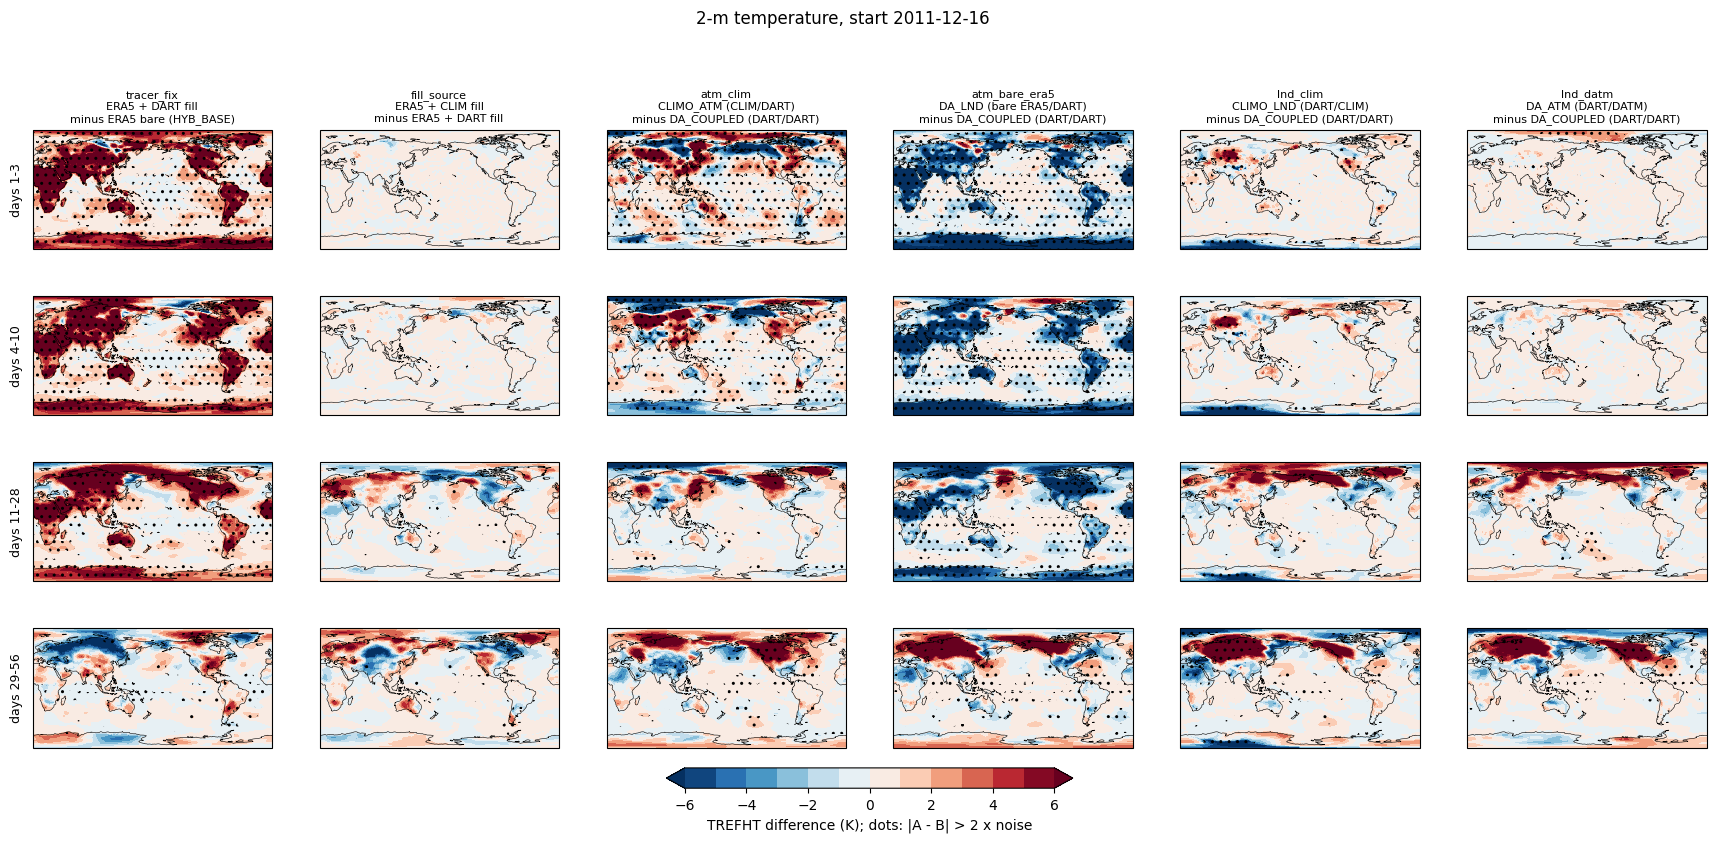

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/maps/maps_T850.png


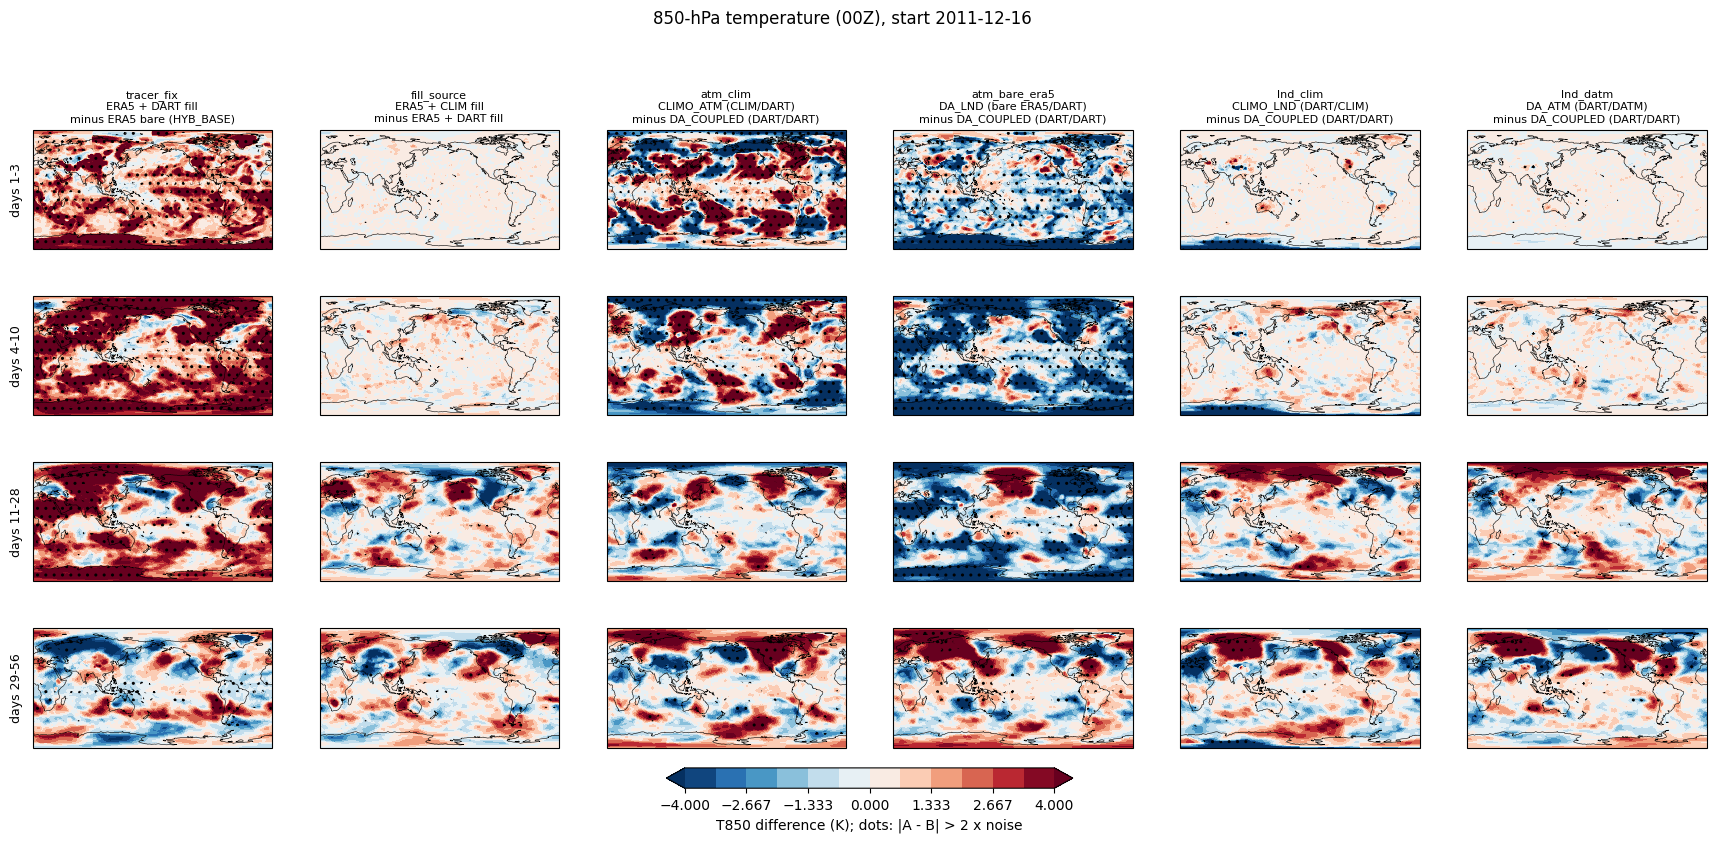

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/maps/maps_TOZ.png


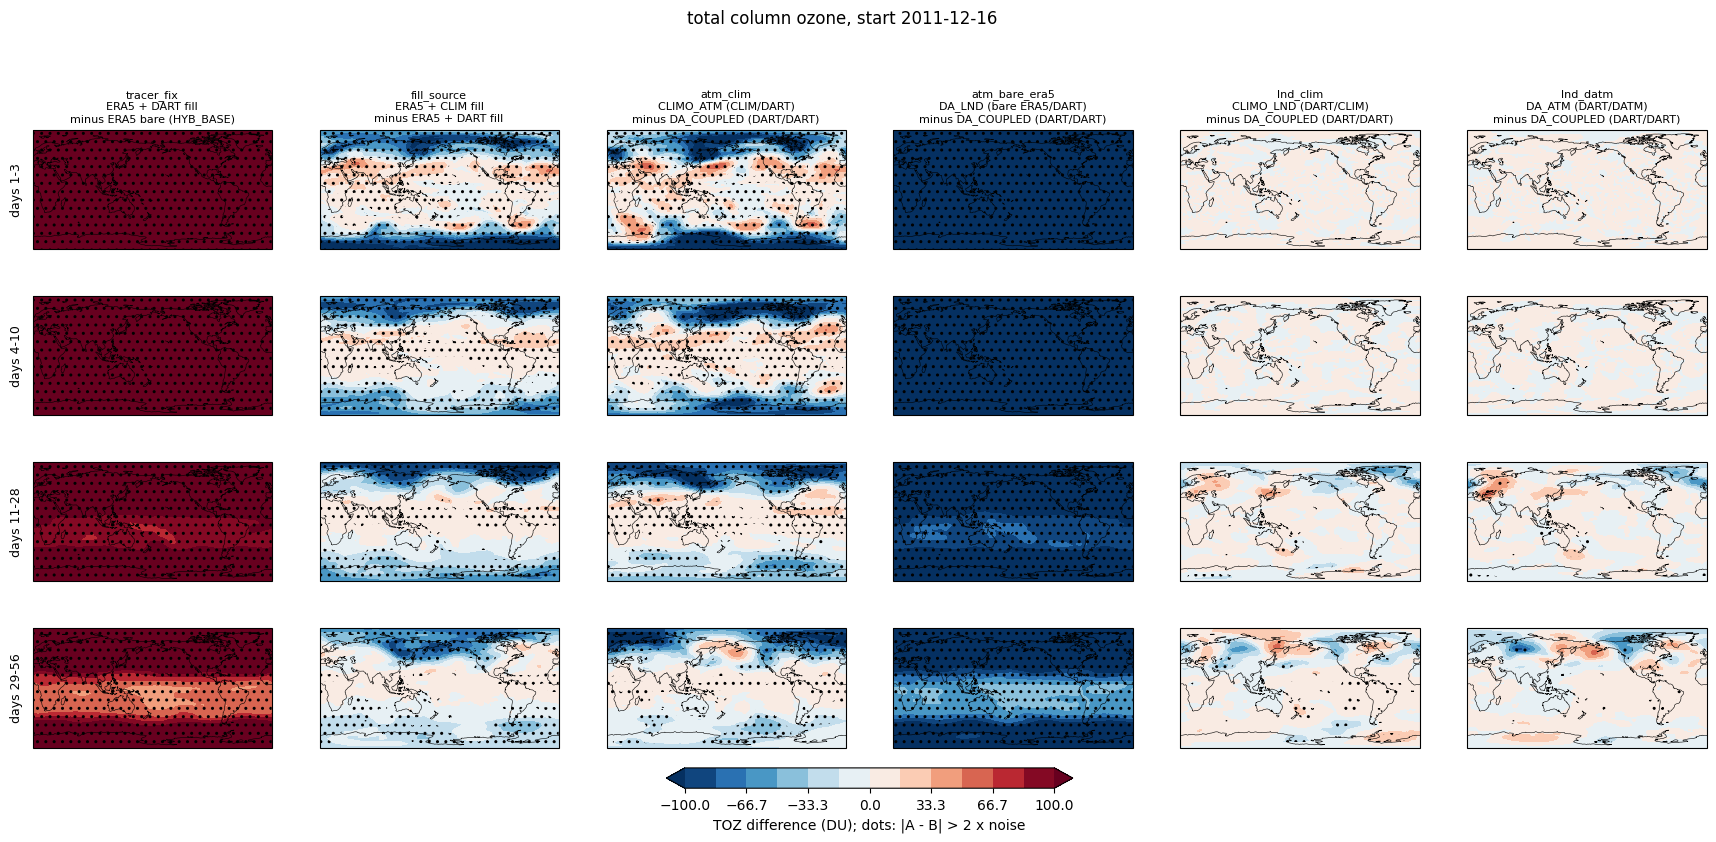

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/maps/maps_FLDS.png


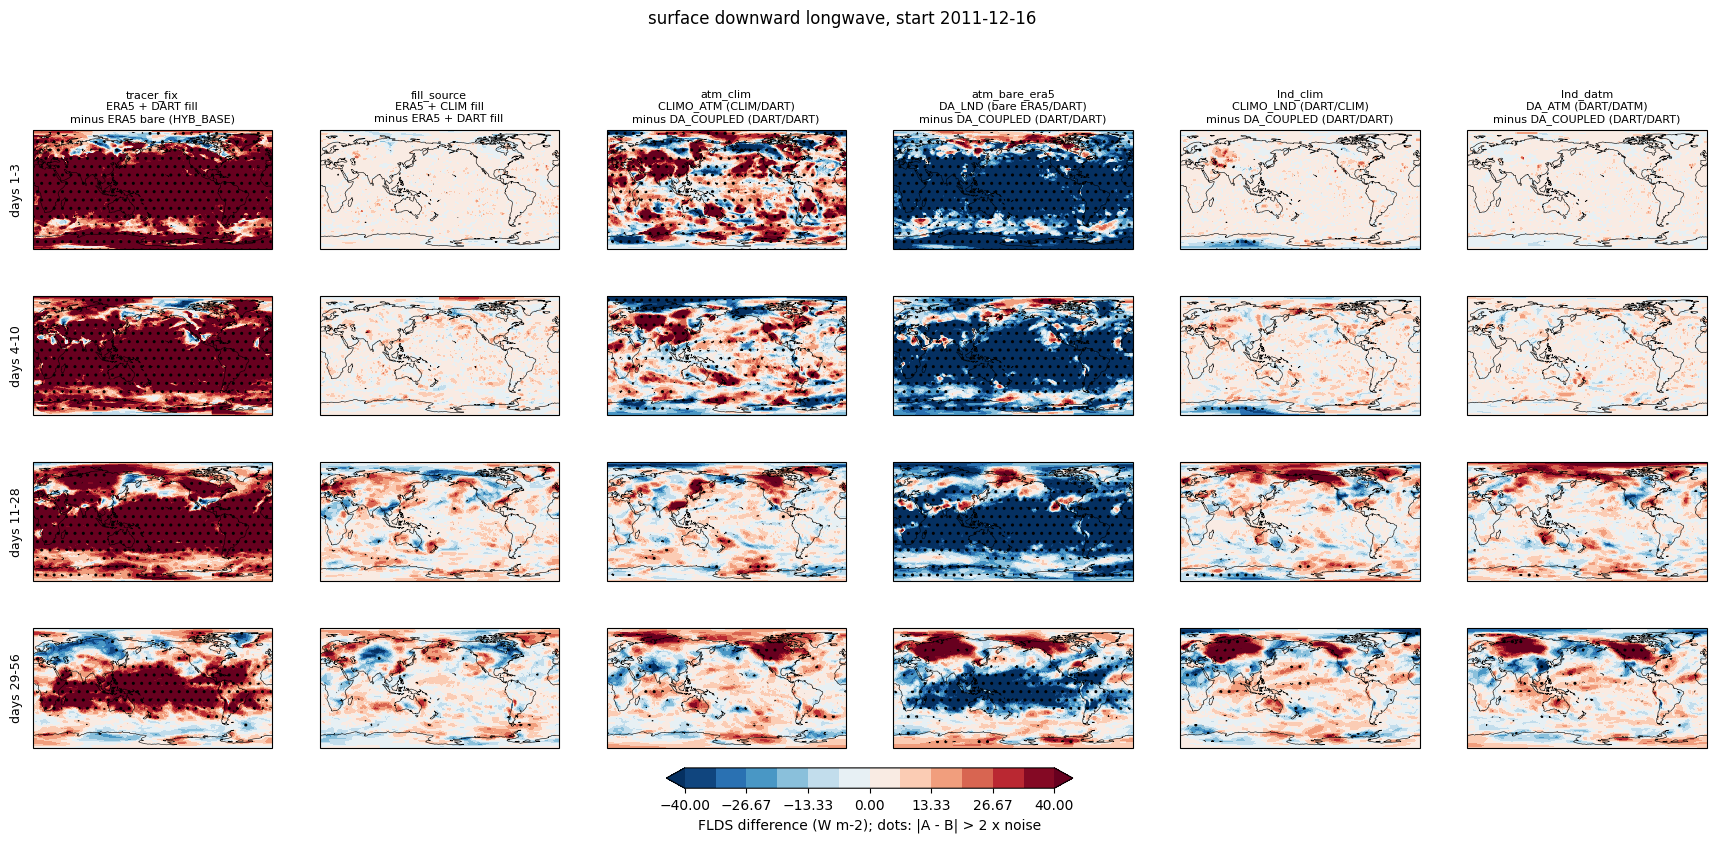

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/maps/maps_PRECT.png


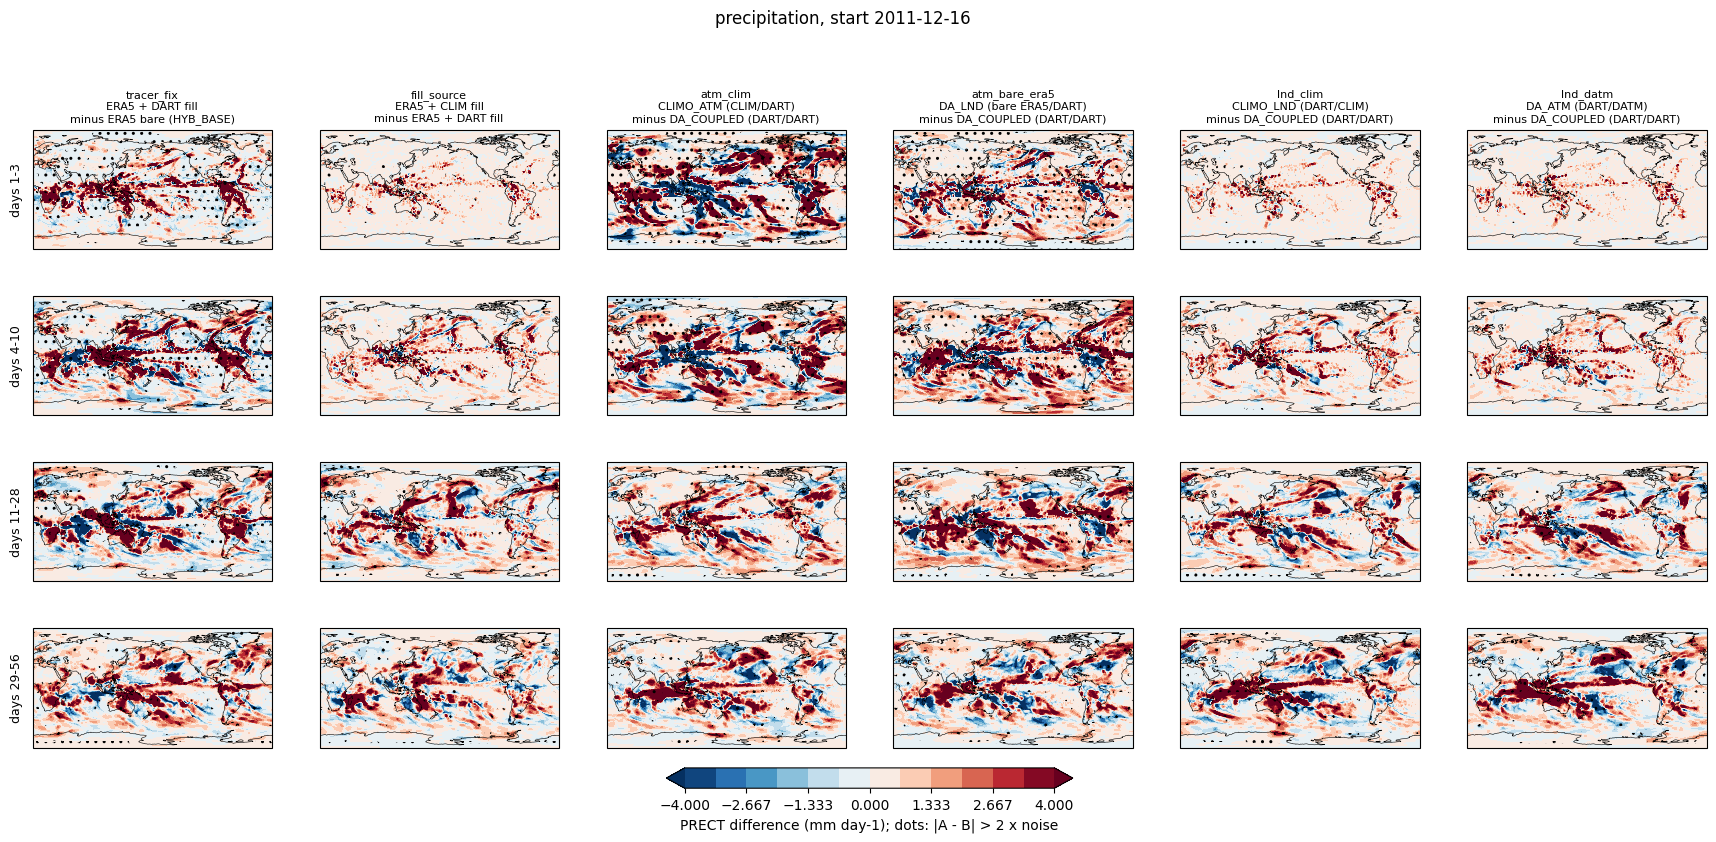

In [5]:
def plot_maps(v):
    ds = maps[v]
    lim = LIMITS.get(v) or float(np.nanpercentile(np.abs(ds["difference"]), 98))
    levels = np.linspace(-lim, lim, 13)
    nr, nc = len(WINDOWS), len(COMPARISON_KEYS)
    fig, axes = plt.subplots(nr, nc, figsize=(3.6 * nc, 2.0 * nr + 0.8),
                             subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)), squeeze=False)
    for j, c in enumerate(COMPARISON_KEYS):
        a, b, _ = COMPARISONS[c]
        for i, w in enumerate(WINDOWS):
            ax = axes[i, j]
            d = ds["difference"].sel(comparison=c, window=w)
            cf = ax.contourf(d.lon, d.lat, d, levels=levels, cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree())
            sig = (np.abs(d) > 2 * ds["noise"].sel(window=w)).astype(float)
            ax.contourf(d.lon, d.lat, sig, levels=[0.5, 1.5], hatches=[".."], colors="none", transform=ccrs.PlateCarree())
            ax.coastlines(lw=0.4)
            if i == 0:
                ax.set_title(f"{c}\n{RUNS[a].label}\nminus {RUNS[b].label}", fontsize=8)
            if j == 0:
                ax.text(-0.04, 0.5, w, transform=ax.transAxes, rotation=90, ha="right", va="center", fontsize=9)
    fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.03, pad=0.03,
                 label=f"{v} difference ({ds.attrs['units']}); dots: |A - B| > 2 x noise")
    fig.suptitle(f"{ds.attrs['long_name']}, start {INIT}", y=0.995)
    save(fig, f"maps_{v}.png")
    plt.show()


for v in VARIABLES:
    plot_maps(v)